# Coulomb repulsion from a *local* constraint: a test on harmonium
### Can the nonlocal $1/r_{12}$ be replaced by a sparse, nearest-neighbour Poisson equation on a 3D grid?

**The idea.** Instead of summing $1/|\mathbf r_i-\mathbf r_j|$ over all pairs, put a helper field $\phi(\mathbf r)$ on the grid that obeys the *local* constraint
$$-\nabla^2\phi=4\pi\rho .$$
Each charge deposits into $\phi$ at its own cell and reads the force from $\phi$ at its own cell. In 3D, $1/r$ is exactly the Green's function of this local operator, so no information is lost in the continuum; on a grid the interaction becomes the **lattice Green function** of the 7-point Laplacian.

**What this notebook tests** (reference system: *harmonium*, two electrons in a 3D harmonic trap, $\omega=\tfrac12$, where the exact energy is $E=2$):

1. the pair interaction that the constraint generates (discretisation, box size, boundary conditions, self-energy);
2. a mean-field (Hartree–Fock) calculation on a 3D grid whose Hartree potential is solved by the local constraint;
3. the **exact** two-electron energy (via the relative coordinate) using the constraint-generated interaction;
4. the role of the self-term;
5. the cost against the all-pairs sum.

**What it does not test.** A two-electron wavefunction lives on a 6D grid, which is infeasible, so there is no full many-body grid calculation here: test 3 works only because harmonium separates into centre-of-mass and relative motion (so it tests the *interaction the constraint produces*, not its cost benefit). Test 2 is mean-field, so the correlation energy ($E_c=-0.0384$) is untouched by the constraint. Dynamic screening, pseudoparticles and Gauss-law time evolution are not tested.

Runtime: about 2 to 3 minutes on a standard CPU runtime (it took about 2 minutes in my sandbox). The cells marked *(speed knob)* contain the grid-spacing lists; remove their finest entries for a faster pass, or add the finer values mentioned in the comments (about 1.5 minutes extra in total) for one more point on each convergence curve.

In [1]:
import time
import numpy as np, scipy.sparse as sp, scipy.sparse.linalg as spla
import matplotlib.pyplot as plt
from scipy.special import ive, erf
from scipy.fft import dstn, idstn
from scipy.integrate import cumulative_trapezoid
from scipy.linalg import eigh_tridiagonal
trapz = getattr(np, "trapezoid", None) or np.trapz
np.set_printoptions(precision=6, suppress=True)

## 1. Two building blocks

**The lattice Green function.** The constraint on a grid of spacing $h$ is the 7-point stencil $(6\phi_{ijk}-\sum_{\rm nb}\phi)/h^2=4\pi\rho_{ijk}$. A unit point charge in one cell produces the potential $\phi(\mathbf n)=\frac{4\pi}{h}\,G(\mathbf n)$, where $G(\mathbf n)=[(6-\sum\text{shifts})^{-1}]_{\mathbf n,0}$ is the lattice Green function. We compute it exactly from
$$G(\mathbf n)=\int_0^\infty e^{-6t}\,I_{n_1}(2t)I_{n_2}(2t)I_{n_3}(2t)\,dt,$$
with a tail correction. For large $|\mathbf n|$, $G\to1/(4\pi|\mathbf n|)$, so the interaction tends to $1/r$.

**The Poisson solver.** `poisson_dirichlet` solves the stencil equation exactly with a fast sine transform (the transform is just how we invert the *same* local operator quickly; we check this against an explicit sparse conjugate-gradient solve in test 5). Boundary values come from a multipole expansion of the charge (`multipole_bc`), i.e. open boundary conditions for a localised density.

In [2]:
def lattice_G(ns, nt=3000, tmin=1e-7, tmax=1e8):
    # infinite simple-cubic lattice Green function G(n) = int_0^inf prod_i I_{n_i}(2t) e^{-6t} dt  (+ analytic tail)
    ns = np.abs(np.asarray(ns, int)); M = len(ns)
    s = np.linspace(np.log(tmin), np.log(tmax), nt); t = np.exp(s); ds = s[1] - s[0]
    out = np.zeros(M); w = np.full(nt, ds); w[0] = w[-1] = ds/2
    for k in range(0, M, 2000):
        blk = ns[k:k+2000]; f = np.ones((len(blk), nt))
        for d in range(3): f *= ive(blk[:, d][:, None], 2*t[None, :])
        out[k:k+2000] = (f*t[None, :]*w[None, :]).sum(axis=1)
    return out + 2/(4*np.pi)**1.5/np.sqrt(tmax)

def poisson_dirichlet(rho, h, bnd=None):
    # solve (6 phi - sum_nb phi)/h^2 = 4 pi rho on the N^3 interior (7-point local stencil);
    # bnd(X,Y,Z) gives the potential on the shell of boundary planes (None = zero Dirichlet walls)
    N = rho.shape[0]; rhs = 4*np.pi*rho.copy()
    if bnd is not None:
        c = (np.arange(N) - (N-1)/2)*h; xb = (N+1)/2*h
        A, B = np.meshgrid(c, c, indexing='ij'); W = np.full_like(A, xb)
        for sgn, sl in ((-1, 0), (1, -1)):
            rhs[sl, :, :] += bnd(sgn*W, A, B)/h**2
            rhs[:, sl, :] += bnd(A, sgn*W, B)/h**2
            rhs[:, :, sl] += bnd(A, B, sgn*W)/h**2
    k = np.arange(1, N+1); lam1 = (2 - 2*np.cos(np.pi*k/(N+1)))/h**2
    lam = lam1[:, None, None] + lam1[None, :, None] + lam1[None, None, :]
    return idstn(dstn(rhs, type=1)/lam, type=1)

def multipole_bc(Q, p):
    # potential of total charge Q and dipole p about the origin: Q/r + p.r/r^3
    def f(X, Y, Z):
        r = np.sqrt(X**2 + Y**2 + Z**2); return Q/r + (p[0]*X + p[1]*Y + p[2]*Z)/r**3
    return f

def cg_solve(A, b, tol):
    # scipy changed the CG keyword from tol to rtol; support both
    its = [0]
    def cb(xk): its[0] += 1
    try:    x, info = spla.cg(A, b, rtol=tol, callback=cb, maxiter=5000)
    except TypeError: x, info = spla.cg(A, b, tol=tol, callback=cb, maxiter=5000)
    return x, its[0]

In [3]:
# validation of the lattice Green function
g = lattice_G(np.array([[0,0,0],[1,0,0],[1,1,1]]))
print("G(0,0,0) =", np.round(g[0], 7), "  (literature 0.2527310)")
print("defining identity 6 G(0) - 6 G(1,0,0) =", round(6*g[0]-6*g[1], 7), "  (exactly 1)")
print("lattice self-value of the interaction  4 pi G(0)/h = %.4f / h" % (4*np.pi*g[0]))
print("\nlong-range limit, 4 pi |n| G(n) -> 1 (relative deviation falls as 1/n^2):")
for n in (5, 10, 20, 40):
    G = lattice_G(np.array([[n, 0, 0]]))[0]; print(f"   |n|={n:3d}   4 pi |n| G = {4*np.pi*n*G:.5f}")

G(0,0,0) = 0.2527309   (literature 0.2527310)
defining identity 6 G(0) - 6 G(1,0,0) = 0.9999994   (exactly 1)
lattice self-value of the interaction  4 pi G(0)/h = 3.1759 / h

long-range limit, 4 pi |n| G(n) -> 1 (relative deviation falls as 1/n^2):
   |n|=  5   4 pi |n| G = 1.01166
   |n|= 10   4 pi |n| G = 1.00258
   |n|= 20   4 pi |n| G = 1.00063
   |n|= 40   4 pi |n| G = 1.00016


## 2. Test 1 — the pair interaction generated by the constraint

Two unit charges sit on the $x$-axis, symmetric about the centre of a cubic box (half-size $L$, spacing $h=0.25$). We compare the potential the constraint gives at the second charge with $1/r$, for three situations: the **infinite lattice** (discretisation error only), a box with **zero Dirichlet walls**, and a box with **multipole (monopole+dipole) boundary values**. Then we look at the spurious *self-potential* of a single charge, which depends on where it sits.

relative error of the pair potential against 1/r
   r     infinite lattice | L=4: zero BC  multipole | L=8: zero BC  multipole | L=12: zero BC  multipole
   0.50       7.8e-02    |    2.5e-02    7.8e-02 |    2.5e-02    7.8e-02 |    4.2e-02    7.8e-02
   1.00       2.0e-02    |    1.8e-01    2.0e-02 |    8.6e-02    2.0e-02 |    5.1e-02    2.0e-02
   2.00       4.1e-03    |    3.9e-01    3.2e-03 |    2.1e-01    4.1e-03 |    1.4e-01    4.1e-03
   4.00       9.9e-04    |    7.1e-01    2.5e-02 |    4.0e-01    5.7e-05 |    2.8e-01    8.4e-04


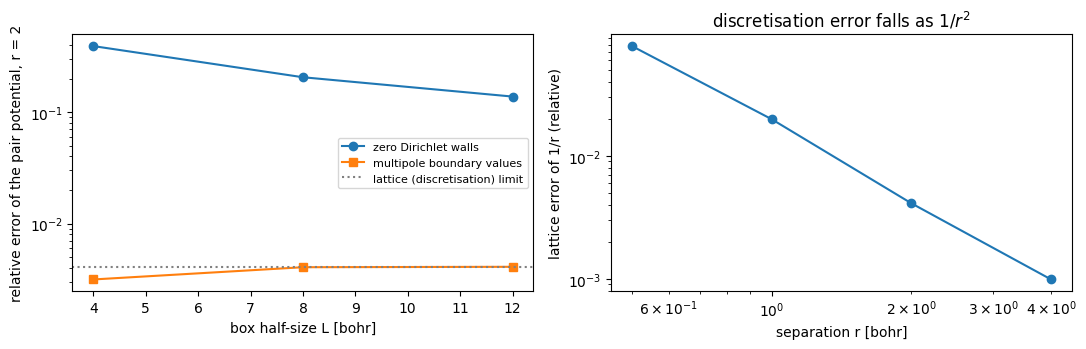

In [4]:
h = 0.25
def grid(L):
    N = int(round(2*L/h)) + 1; return N, (np.arange(N) - (N-1)/2)*h
def point(N, ix, iy, iz, q=1.0):
    rho = np.zeros((N, N, N)); rho[ix, iy, iz] = q/h**3; return rho

seps = (2, 4, 8, 16)                      # separation in grid units  (r = sep*h)
res = {}
for L in (4, 8, 12):
    N, c = grid(L); m = N//2
    for sep in seps:
        i1, i2 = m - sep//2, m + sep//2
        rho = point(N, i1, m, m)
        p0 = poisson_dirichlet(rho, h)[i2, m, m]
        pM = poisson_dirichlet(rho, h, multipole_bc(1.0, np.array([c[i1], 0, 0])))[i2, m, m]
        res[(L, sep)] = (p0, pM)

print("relative error of the pair potential against 1/r")
print("   r     infinite lattice | L=4: zero BC  multipole | L=8: zero BC  multipole | L=12: zero BC  multipole")
for sep in seps:
    r = sep*h; Ginf = 4*np.pi*lattice_G(np.array([[sep, 0, 0]]))[0]/h
    row = f"  {r:5.2f}     {abs(Ginf-1/r)*r:9.1e}   "
    for L in (4, 8, 12):
        p0, pM = res[(L, sep)]; row += f" |  {abs(p0-1/r)*r:9.1e}  {abs(pM-1/r)*r:9.1e}"
    print(row)

# plot error vs box size at r = 2
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
Ls = (4, 8, 12); r = 8*h
ax[0].semilogy(Ls, [abs(res[(L, 8)][0]-1/r)*r for L in Ls], 'o-', label='zero Dirichlet walls')
ax[0].semilogy(Ls, [abs(res[(L, 8)][1]-1/r)*r for L in Ls], 's-', label='multipole boundary values')
ax[0].axhline(abs(4*np.pi*lattice_G(np.array([[8, 0, 0]]))[0]/h - 1/r)*r, color='gray', ls=':', label='lattice (discretisation) limit')
ax[0].set_xlabel('box half-size L [bohr]'); ax[0].set_ylabel('relative error of the pair potential, r = 2'); ax[0].legend(fontsize=8)
rs = np.array(seps)*h; Gi = np.array([4*np.pi*lattice_G(np.array([[s, 0, 0]]))[0]/h for s in seps])
ax[1].loglog(rs, np.abs(Gi-1/rs)*rs, 'o-'); ax[1].set_xlabel('separation r [bohr]'); ax[1].set_ylabel('lattice error of 1/r (relative)')
ax[1].set_title('discretisation error falls as $1/r^2$')
plt.tight_layout(); plt.show()

In [5]:
# spurious position-dependent self-potential of a single unit charge (relative to the infinite-lattice value)
Ginf0 = 4*np.pi*0.2527309/h
L = 8; N, c = grid(L); m = N//2
print("single unit charge at fraction x/L of the way to the wall (box L=8, h=0.25)")
print(f"   x/L    zero-Dirichlet BC     multipole BC      (a typical pair energy at r=2 is 0.5)")
for frac in (0.0, 0.5, 0.8, 0.95):
    ix = m + int(round(frac*(N//2-1))); rho = point(N, ix, m, m)
    p0 = poisson_dirichlet(rho, h)[ix, m, m] - Ginf0
    pM = poisson_dirichlet(rho, h, multipole_bc(1.0, np.array([c[ix], 0, 0])))[ix, m, m] - Ginf0
    print(f"  {frac:5.2f}    {p0:+.4f}             {pM:+.2e}")

single unit charge at fraction x/L of the way to the wall (box L=8, h=0.25)
   x/L    zero-Dirichlet BC     multipole BC      (a typical pair energy at r=2 is 0.5)
   0.00    -0.1059             +1.95e-07
   0.50    -0.1351             -8.12e-03
   0.80    -0.2548             -8.79e-02
   0.95    -0.5032             -3.06e-01


**Reading the results.** With multipole boundary values and a roomy box, the only remaining error is the lattice discretisation, which falls as $1/r^2$. With zero walls the image charges screen the interaction wrongly and the error decays only like $1/L$. The self-potential of a charge is position-dependent near the walls, which acts like a spurious one-body potential. Practical rule: use open boundary conditions and keep the density well inside the box.

## 3. Exact references for harmonium
Harmonium separates into centre-of-mass and relative motion. The relative radial equation $-u''+(\tfrac14\omega^2r^2+1/r)u=\varepsilon u$ gives the exact $E=\tfrac32\omega+\varepsilon$ (exactly $2$ at $\omega=\tfrac12$). The Hartree–Fock reference solves the spherical radial equation self-consistently (for two electrons the Fock operator is $h+\tfrac12 v_H[n]$, and $E_{\rm ee}=\tfrac14\int n\,v_H[n]$). Both use tridiagonal eigensolves.

In [6]:
def radial_reference(w=0.5, R=14.0, n=12000):
    # exact two-electron harmonium energy and spherical restricted HF energy
    r = np.linspace(0, R, n+2)[1:-1]; dr = r[1] - r[0]
    def lowest(pot, coef):
        d = 2*coef/dr**2 + pot; e = -coef/dr**2*np.ones(n-1)
        ev, V = eigh_tridiagonal(d, e, select='i', select_range=(0, 0)); return ev[0], V[:, 0]
    eps, _ = lowest(w**2*r**2/4 + 1/r, 1.0); Eex = 1.5*w + eps
    u = np.exp(-w*r**2/2)*r; u /= np.sqrt(np.sum(u**2)*dr)
    def vh(u):
        nrho = 2*u**2/(4*np.pi*r**2); q = cumulative_trapezoid(nrho*4*np.pi*r**2, r, initial=0)
        tot = trapz(nrho*4*np.pi*r, r); out = tot - cumulative_trapezoid(nrho*4*np.pi*r, r, initial=0)
        return nrho, q/r + out
    for it in range(300):
        nrho, v = vh(u); e, un = lowest(0.5*w**2*r**2 + 0.5*v, 0.5); un = np.abs(un)/np.sqrt(np.sum(un**2)*dr)
        if np.abs(un - u).max() < 1e-13: u = un; break
        u = 0.5*u + 0.5*un
    nrho, v = vh(u)
    d2u = (np.r_[u[1:], 0] - 2*u + np.r_[0, u[:-1]])/dr**2
    kin = np.sum(u*(-0.5*d2u))*dr; pot = np.sum(u**2*0.5*w**2*r**2)*dr
    Jee = 0.25*trapz(nrho*v*4*np.pi*r**2, r)
    return Eex, 2*(kin + pot) + Jee

E_exact, E_HF = radial_reference()
print(f"exact two-electron energy   E = {E_exact:.7f}   (analytic: 2)")
print(f"Hartree-Fock energy         E = {E_HF:.7f}   (literature: 2.0384)")
print(f"correlation energy         E_c = {E_exact-E_HF:.6f}")

exact two-electron energy   E = 2.0000000   (analytic: 2)
Hartree-Fock energy         E = 2.0384388   (literature: 2.0384)
correlation energy         E_c = -0.038439


## 4. Test 2 — mean-field harmonium on a 3D grid, Hartree potential from the local constraint
The orbital lives on a cubic grid with a 7-point finite-difference kinetic energy. At every SCF step the Hartree potential is obtained from the *constraint* (`poisson_dirichlet`), with either zero walls or multipole boundary values.

In [7]:
SC = 4*np.pi*0.2527309 - 2.380079          # lattice self-value minus cell-average self-value (units of 1/h); used in test 4

def grid_hf(h, L, bc='multipole', w=0.5, tol=1e-9, maxit=60, selfcorr=False):
    N = int(round(2*L/h)) + 1; c = (np.arange(N) - (N-1)/2)*h
    X, Y, Z = np.meshgrid(c, c, c, indexing='ij'); r2 = X**2 + Y**2 + Z**2
    I = sp.identity(N, format='csr'); T1 = (sp.diags([-2*np.ones(N), np.ones(N-1), np.ones(N-1)], [0, 1, -1])/h**2).tocsr()
    Lap = sp.kron(sp.kron(T1, I), I) + sp.kron(sp.kron(I, T1), I) + sp.kron(sp.kron(I, I), T1)
    Tk = -0.5*Lap.tocsr(); Vtrap = (0.5*w**2*r2).ravel()
    phi = np.exp(-w*r2/2).ravel(); phi /= np.sqrt(np.sum(phi**2)*h**3); Eold = 0
    def hartree(phi):
        n = 2*(phi**2).reshape(N, N, N)
        bnd = None if bc == 'zero' else multipole_bc(np.sum(n)*h**3, [0, 0, 0])
        vH = poisson_dirichlet(n, h, bnd)
        if selfcorr: vH = vH - SC*h**2*n
        return n, vH
    for it in range(maxit):
        n, vH = hartree(phi)
        e, V = spla.eigsh(Tk + sp.diags(Vtrap + 0.5*vH.ravel()), k=1, which='SA', v0=phi, tol=1e-10)
        new = V[:, 0]*np.sign(V[:, 0].sum()); new /= np.sqrt(np.sum(new**2)*h**3)
        phi = 0.5*phi + 0.5*new if it > 0 else new; phi /= np.sqrt(np.sum(phi**2)*h**3)
        n, vH = hartree(phi)
        kin = np.sum(phi*(Tk@phi))*h**3; pot = np.sum(phi**2*Vtrap)*h**3; Jee = 0.25*np.sum(n*vH)*h**3
        E = 2*(kin + pot) + Jee
        if abs(E - Eold) < tol: break
        Eold = E
    return E, it + 1, N

(a) grid spacing scan, multipole boundary values, box half-size L = 6
      h      N^3     E_HF(grid)     error vs radial HF
    0.60    21^3    2.030534     -7.905e-03     (1s)
    0.50    25^3    2.032931     -5.508e-03     (1s)
    0.40    31^3    2.034904     -3.535e-03     (2s)
    0.30    41^3    2.036446     -1.993e-03     (9s)
    0.25    49^3    2.037054     -1.385e-03     (11s)
   log-log slope of |error| vs h: [1.98 1.99 1.99 2.  ]
   h^2 Richardson extrapolation of the two finest grids: error -3.6e-06

(b) box-size scan at h = 0.5
     L    multipole BC error     zero-wall BC error
     3      +2.661e-02          -2.235e-01
     4      -4.365e-03          -1.989e-01
     5      -5.510e-03          -1.646e-01
     6      -5.508e-03          -1.401e-01
     8      -5.490e-03          -1.083e-01
    10      -5.482e-03          -8.873e-02

   for scale: the correlation energy is -0.0384


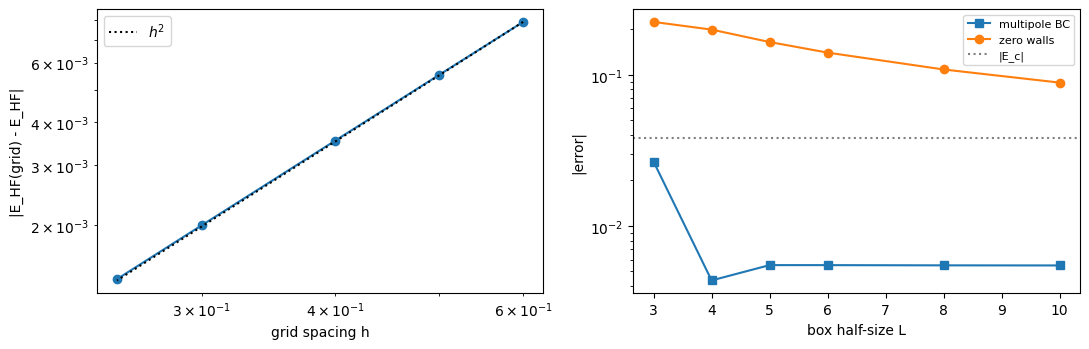

In [8]:
H_VALUES = (0.6, 0.5, 0.4, 0.3, 0.25)           # (speed knob) drop 0.25 for a faster run
print("(a) grid spacing scan, multipole boundary values, box half-size L = 6")
print("      h      N^3     E_HF(grid)     error vs radial HF")
hf_err = []
for h_ in H_VALUES:
    t0 = time.time(); E, it, N = grid_hf(h_, 6, 'multipole'); hf_err.append(E - E_HF)
    print(f"    {h_:4.2f}   {N:3d}^3    {E:.6f}     {E-E_HF:+.3e}     ({time.time()-t0:.0f}s)")
sl = [np.log(abs(hf_err[i+1]/hf_err[i]))/np.log(H_VALUES[i+1]/H_VALUES[i]) for i in range(len(H_VALUES)-1)]
print("   log-log slope of |error| vs h:", np.round(sl, 2))
(h1, a1), (h2, a2) = (H_VALUES[-2], hf_err[-2]), (H_VALUES[-1], hf_err[-1]); cc = (a2 - a1)/(h2**2 - h1**2)
print(f"   h^2 Richardson extrapolation of the two finest grids: error {a2 - cc*h2**2:+.1e}")

print("\n(b) box-size scan at h = 0.5")
print("     L    multipole BC error     zero-wall BC error")
box = {}
for L in (3, 4, 5, 6, 8, 10):
    Em, _, _ = grid_hf(0.5, L, 'multipole'); Ez, _, _ = grid_hf(0.5, L, 'zero'); box[L] = (Em - E_HF, Ez - E_HF)
    print(f"   {L:3d}      {Em-E_HF:+.3e}          {Ez-E_HF:+.3e}")
print(f"\n   for scale: the correlation energy is {E_exact-E_HF:+.4f}")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].loglog(H_VALUES, np.abs(hf_err), 'o-'); ax[0].loglog(H_VALUES, np.abs(hf_err[0])*(np.array(H_VALUES)/H_VALUES[0])**2, 'k:', label='$h^2$')
ax[0].set_xlabel('grid spacing h'); ax[0].set_ylabel('|E_HF(grid) - E_HF|'); ax[0].legend()
Ls = sorted(box); ax[1].semilogy(Ls, [abs(box[L][0]) for L in Ls], 's-', label='multipole BC'); ax[1].semilogy(Ls, [abs(box[L][1]) for L in Ls], 'o-', label='zero walls')
ax[1].axhline(abs(E_exact-E_HF), color='gray', ls=':', label='|E_c|'); ax[1].set_xlabel('box half-size L'); ax[1].set_ylabel('|error|'); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Reading the results.** With open boundary values the grid mean-field energy converges at second order in $h$, and Richardson extrapolation recovers the radial HF energy to a few $10^{-6}$. The box must be large enough to contain the density ($L\ge5$ here). With zero walls the error is several times the correlation energy itself and recovers only like $1/L$.

## 5. Test 3 — the exact two-electron energy with the constraint-generated interaction
Using the centre-of-mass separation of harmonium, the exact two-electron problem becomes a *single* 3D problem in the relative coordinate $\mathbf r=\mathbf r_1-\mathbf r_2$:
$$H_{\rm rel}=-\nabla_h^2+\tfrac14\omega^2r^2+V(\mathbf r),\qquad E=\tfrac32\omega+\varepsilon_{\min}.$$
We compare two choices of $V$ on the cubic grid: the **constraint-generated lattice Coulomb interaction** $V=4\pi G(\mathbf n)/h$ (translation-invariant, infinite lattice), and the **standard** point value $1/r$ with the cell average $2.380/h$ at the origin.

In [9]:
def cube_avg_inv_r(n=400):
    # average of 1/|x| over the unit cube centred at the origin (midpoint rule + Richardson)
    def mid(n):
        c = (np.arange(n)+0.5)/n - 0.5; tot = 0.0
        for i in range(n): tot += np.sum(1/np.sqrt(c[i]**2 + c[:, None]**2 + c[None, :]**2))
        return tot/n**3
    return 2*mid(n) - mid(n//2)

CELL0 = cube_avg_inv_r()
print("cell-averaged 1/r at the origin = %.4f / h   |   lattice (constraint) value 4 pi G(0) = %.4f / h" % (CELL0, 4*np.pi*0.2527309))

def relative_problem(h, Lr=10.0, w=0.5, potential='lattice'):
    N = int(round(2*Lr/h)) + 1; m = (N-1)//2; n1 = np.arange(N) - m
    I = sp.identity(N, format='csr'); T1 = (sp.diags([-2*np.ones(N), np.ones(N-1), np.ones(N-1)], [0, 1, -1])/h**2).tocsr()
    Lap = sp.kron(sp.kron(T1, I), I) + sp.kron(sp.kron(I, T1), I) + sp.kron(sp.kron(I, I), T1)
    X, Y, Z = np.meshgrid(n1, n1, n1, indexing='ij'); nn = np.stack([np.abs(X).ravel(), np.abs(Y).ravel(), np.abs(Z).ravel()], axis=1)
    r2 = (nn**2).sum(axis=1)*h**2
    if potential == 'lattice':
        uk, inv = np.unique(np.sort(nn, axis=1), axis=0, return_inverse=True)
        V = (4*np.pi*lattice_G(uk)/h)[inv.ravel()]
    else:
        rr = np.sqrt(r2); V = np.where(rr > 0, 1/np.where(rr > 0, rr, 1), 0.0); V[r2 == 0] = CELL0/h
    H = -Lap + sp.diags(0.25*w**2*r2 + V)
    return 1.5*w + spla.eigsh(H.tocsc(), k=1, which='SA', tol=1e-10)[0][0], N

cell-averaged 1/r at the origin = 2.3801 / h   |   lattice (constraint) value 4 pi G(0) = 3.1759 / h


exact E = 2 (omega = 1/2).  relative-coordinate grid, half-size 10
     h      N^3     constraint lattice Coulomb: E      error       cell-averaged 1/r: E      error
   0.60    34^3         1.997943                  -2.057e-03      1.995911             -4.089e-03   (5s)
   0.50    41^3         1.998568                  -1.432e-03      1.997183             -2.817e-03   (5s)
   0.40    51^3         1.999082                  -9.181e-04      1.998212             -1.788e-03   (12s)
   0.30    68^3         1.999484                  -5.165e-04      1.999002             -9.975e-04   (35s)
   constraint lattice: log-log slope of |error| vs h: [1.99 1.99 2.  ]
   cell-averaged  : log-log slope of |error| vs h: [2.04 2.04 2.03]
   error ratio cell-averaged / constraint: [1.99 1.97 1.95 1.93]


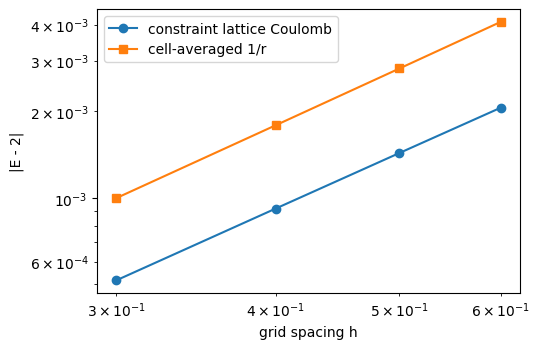

In [10]:
H_REL = (0.6, 0.5, 0.4, 0.3)                    # (speed knob) add 0.25 for one more point (about 35 s extra)
print("exact E = 2 (omega = 1/2).  relative-coordinate grid, half-size 10")
print("     h      N^3     constraint lattice Coulomb: E      error       cell-averaged 1/r: E      error")
rel = []
for h_ in H_REL:
    t0 = time.time(); Ec, N = relative_problem(h_, potential='lattice'); Ecell, _ = relative_problem(h_, potential='cell'); rel.append((h_, Ec-2, Ecell-2))
    print(f"   {h_:4.2f}   {N:3d}^3         {Ec:.6f}                  {Ec-2:+.3e}      {Ecell:.6f}             {Ecell-2:+.3e}   ({time.time()-t0:.0f}s)")
hs = np.array([r[0] for r in rel])
for k, name in ((1, 'constraint lattice'), (2, 'cell-averaged  ')):
    e = np.abs([r[k] for r in rel]); print(f"   {name}: log-log slope of |error| vs h:", np.round(np.diff(np.log(e))/np.diff(np.log(hs)), 2))
print("   error ratio cell-averaged / constraint:", np.round(np.abs([r[2] for r in rel])/np.abs([r[1] for r in rel]), 2))
plt.figure(figsize=(5.5, 3.6)); plt.loglog(hs, np.abs([r[1] for r in rel]), 'o-', label='constraint lattice Coulomb'); plt.loglog(hs, np.abs([r[2] for r in rel]), 's-', label='cell-averaged 1/r')
plt.xlabel('grid spacing h'); plt.ylabel('|E - 2|'); plt.legend(); plt.tight_layout(); plt.show()

**Reading the results.** Both choices converge at second order, so the electron–electron cusp does not spoil the convergence order on this grid. The constraint-generated interaction has roughly half the error of the cell-averaged one. A plausible reason (not tested here) is that its lattice Green function is consistent with the lattice kinetic operator.

## 6. Test 4 — the self-term
The field solve includes every cell's *own* contribution, which is $4\pi G(0)/h=3.176/h$ times the cell's charge. A pair sum that skips $j=i$ includes none, and a cell-averaged treatment would use $2.380/h$. For a smooth density this on-site term dominates the error of the local solve. We compare, against the analytic Hartree potential of a Gaussian density, (i) a pair sum excluding self, (ii) a pair sum with the cell-average self term, (iii) the stencil solve, and (iv) the stencil with the lattice self value replaced by the cell average. Then we check what that replacement does to the Hartree–Fock *energy*.

In [11]:
w_g = 0.5
def analytic_phi(R):
    R = np.asarray(R); out = np.empty_like(R); nz = R > 1e-12
    out[nz] = 2*erf(np.sqrt(w_g)*R[nz])/R[nz]; out[~nz] = 2*2*np.sqrt(w_g/np.pi); return out
Gl0 = 4*np.pi*0.2527309
H_SELF = (1.0, 0.75, 0.5)                       # (speed knob) add 0.375 for a finer point (about 1 min extra)
print("max error of the Hartree potential of rho = 2 (w/pi)^1.5 exp(-w r^2) (total charge 2) against the analytic erf form")
print("     h    N   pair sum excl. self | pair sum + cell-avg self | stencil solve | stencil, self value swapped")
for h_ in H_SELF:
    L = 6.0; N = int(round(2*L/h_)) + 1; c = (np.arange(N) - (N-1)/2)*h_; X, Y, Z = np.meshgrid(c, c, c, indexing='ij')
    R = np.sqrt(X**2 + Y**2 + Z**2); rho = 2*(w_g/np.pi)**1.5*np.exp(-w_g*R**2); P = np.stack([X.ravel(), Y.ravel(), Z.ravel()], 1)
    q = rho.ravel()*h_**3; phi_d = np.empty(len(P))
    for k in range(0, len(P), 400):
        d = np.sqrt(((P[k:k+400, None, :] - P[None, :, :])**2).sum(-1)); d[d == 0] = np.inf; phi_d[k:k+400] = (q[None, :]/d).sum(1)
    ph_an = analytic_phi(R.ravel()); ph_s = poisson_dirichlet(rho, h_, multipole_bc(rho.sum()*h_**3, [0, 0, 0])).ravel()
    ph_s2 = ph_s - Gl0*h_**2*rho.ravel() + CELL0*h_**2*rho.ravel()
    print(f"  {h_:5.3f} {N:3d}      {np.abs(phi_d-ph_an).max():.2e}          {np.abs(phi_d+CELL0*h_**2*rho.ravel()-ph_an).max():.2e}        {np.abs(ph_s-ph_an).max():.2e}        {np.abs(ph_s2-ph_an).max():.2e}")

print("\nthe same replacement inside the Hartree-Fock energy (grid error vs radial HF):")
print("     h     error (stencil as is)    error (self value swapped)")
rows = []
for h_ in H_VALUES:
    E1, _, _ = grid_hf(h_, 6, 'multipole'); E2, _, _ = grid_hf(h_, 6, 'multipole', selfcorr=True); rows.append((h_, E1-E_HF, E2-E_HF))
    print(f"   {h_:4.2f}      {E1-E_HF:+.3e}               {E2-E_HF:+.3e}")
for k, name in ((1, 'as is'), (2, 'swapped')):
    (h1, a1), (h2, a2) = [(r[0], r[k]) for r in rows[-2:]]; cc = (a2 - a1)/(h2**2 - h1**2); print(f"   h^2-extrapolated error ({name}): {a2 - cc*h2**2:+.1e}")

max error of the Hartree potential of rho = 2 (w/pi)^1.5 exp(-w r^2) (total charge 2) against the analytic erf form
     h    N   pair sum excl. self | pair sum + cell-avg self | stencil solve | stencil, self value swapped
  1.000  13      3.43e-01          4.04e-02        8.79e-02        1.32e-02
  0.750  17      1.97e-01          2.72e-02        4.72e-02        9.64e-03
  0.500  25      8.90e-02          1.34e-02        2.03e-02        4.92e-03

the same replacement inside the Hartree-Fock energy (grid error vs radial HF):
     h     error (stencil as is)    error (self value swapped)
   0.60      -7.905e-03               -1.283e-02
   0.50      -5.508e-03               -8.909e-03
   0.40      -3.535e-03               -5.700e-03
   0.30      -1.993e-03               -3.206e-03
   0.25      -1.385e-03               -2.226e-03
   h^2-extrapolated error (as is): -3.6e-06
   h^2-extrapolated error (swapped): +6.2e-07


**Reading the results.** Swapping the lattice on-site value for the cell average makes the Hartree *potential* markedly more accurate (about 4x at $h=0.5$), yet it makes the Hartree–Fock *energy* worse. The finite-difference kinetic-energy error partly cancels the lattice Hartree error, so improving one piece alone exposes the other. After $h^2$ extrapolation both variants are accurate to a few $10^{-6}$. Do not tune one ingredient in isolation.

## 7. Test 5 — cost, and is the fast solver really the local one?
We time the all-pairs sum against the stencil solve for growing grids, and check that the fast sine-transform solver agrees with an explicit **sparse 7-point stencil + conjugate gradients** solution (genuinely local operations).

Hartree potential of a Gaussian on an N^3 grid (h=0.5)
    N   points   pair sum [s]   fast solve [s]   CG on stencil [s] (iters)   |phi_fast - phi_CG|
    9     729       0.036         0.0009          0.002 (  25)            1.8e-15
   13    2197       0.237         0.0013          0.004 (  42)            2.0e-13
   17    4913       1.229         0.0010          0.005 (  55)            2.2e-13
   21    9261       5.470         0.0027          0.016 (  68)            3.6e-13
   25   15625      13.833         0.0023          0.024 (  80)            2.5e-13


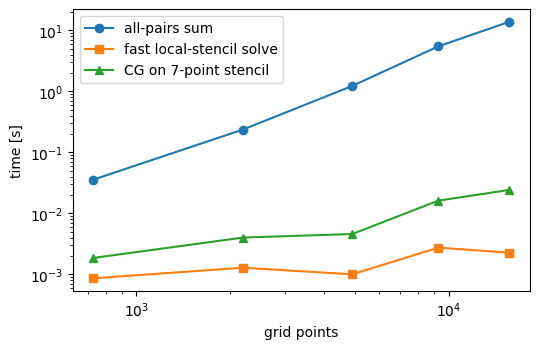

empirical exponent of the all-pairs sum: 1.98


In [12]:
w_c = 0.5; hc = 0.5
print("Hartree potential of a Gaussian on an N^3 grid (h=0.5)")
print("    N   points   pair sum [s]   fast solve [s]   CG on stencil [s] (iters)   |phi_fast - phi_CG|")
cost = []
for N in (9, 13, 17, 21, 25):
    c = (np.arange(N) - (N-1)/2)*hc; X, Y, Z = np.meshgrid(c, c, c, indexing='ij'); P = np.stack([X.ravel(), Y.ravel(), Z.ravel()], 1)
    rho = 2*(w_c/np.pi)**1.5*np.exp(-w_c*(X**2 + Y**2 + Z**2))
    t0 = time.time(); q = rho.ravel()*hc**3
    for k in range(0, len(P), 500):
        d = np.sqrt(((P[k:k+500, None, :] - P[None, :, :])**2).sum(-1)); d[d == 0] = np.inf; _ = (q[None, :]/d).sum(1)
    td = time.time() - t0
    bc = multipole_bc(rho.sum()*hc**3, [0, 0, 0])
    t0 = time.time(); phi_f = poisson_dirichlet(rho, hc, bc); tf = time.time() - t0
    I = sp.identity(N, format='csr'); T1 = (sp.diags([2*np.ones(N), -np.ones(N-1), -np.ones(N-1)], [0, 1, -1])/hc**2).tocsr()
    A = (sp.kron(sp.kron(T1, I), I) + sp.kron(sp.kron(I, T1), I) + sp.kron(sp.kron(I, I), T1)).tocsr()
    rhs = 4*np.pi*rho.copy(); xb = (N+1)/2*hc; A2, B2 = np.meshgrid(c, c, indexing='ij'); Wp = np.full_like(A2, xb)
    for sgn, sl in ((-1, 0), (1, -1)):
        rhs[sl, :, :] += bc(sgn*Wp, A2, B2)/hc**2; rhs[:, sl, :] += bc(A2, sgn*Wp, B2)/hc**2; rhs[:, :, sl] += bc(A2, B2, sgn*Wp)/hc**2
    t0 = time.time(); phi_c, its = cg_solve(A, rhs.ravel(), 1e-12); tc = time.time() - t0
    cost.append((N**3, td, tf, tc))
    print(f"  {N:3d}  {N**3:6d}   {td:9.3f}     {tf:10.4f}      {tc:9.3f} ({its:4d})            {np.abs(phi_f.ravel()-phi_c).max():.1e}")
cost = np.array(cost); plt.figure(figsize=(5.5, 3.6))
plt.loglog(cost[:, 0], cost[:, 1], 'o-', label='all-pairs sum'); plt.loglog(cost[:, 0], cost[:, 2], 's-', label='fast local-stencil solve')
plt.loglog(cost[:, 0], cost[:, 3], '^-', label='CG on 7-point stencil'); plt.xlabel('grid points'); plt.ylabel('time [s]'); plt.legend(); plt.tight_layout(); plt.show()
print("empirical exponent of the all-pairs sum:", round(np.polyfit(np.log(cost[:, 0]), np.log(cost[:, 1]), 1)[0], 2))

## 8. Take-aways, limits, and what to try next

* In 3D the local Poisson constraint reproduces Coulomb repulsion on a grid with **second-order** accuracy in $h$, both for the mean-field Hartree potential and for the pair interaction in the exact two-electron problem.
* **Boundary conditions are the critical ingredient.** Open (multipole) boundary values reduce the box effect to the lattice error; zero walls are wrong by several times the correlation energy and recover only like $1/L$, and a spurious self-potential appears near walls. Keep the density well inside the box.
* The on-site **self-term** dominates the potential error but tuning it alone can worsen the *energy* through cancellation with the finite-difference kinetic error; compare total energies, and extrapolate in $h^2$.
* The cost of the pair sum grows like (points)$^2$ while the local solve is nearly flat here; the sine-transform solver is the same local operator as the sparse stencil (agreement $\sim10^{-13}$).
* **Limits.** No full many-body grid calculation (6D), so the two-electron test uses the centre-of-mass separation of harmonium; the mean-field test has no correlation; only $\omega=\tfrac12$, singlet, localised density; the lattice Green function is evaluated to about $10^{-6}$; the dynamic screening part, pseudoparticles and Gauss-law time evolution are not tested.

**Exercises.** (1) Repeat for other $\omega$ (exact energies are known for special values). (2) Add dipole/quadrupole terms to `multipole_bc` and find how close to the wall a charge may sit. (3) Replace the sine-transform solve by a multigrid V-cycle and compare the cost scaling. (4) Replace the 7-point stencil by a higher-order one and see whether the order of convergence improves. (5) Move to a many-electron density (e.g. a closed-shell atom) and test whether the optimal self-term treatment changes.